# Experiment #7: MLP Neural Network for Iris Flower Classification

**Dataset:** Iris (`iris.csv`) - 150 flowers, 4 measurements + species  
**Name:** Adithya Rajesh  |  **Class:** R3AI  |  **Roll No:** B25CTA07  |  **Date:** 13-10-2026

**Objective:** Build a **Multi-Layer Perceptron (MLP)** neural network to classify iris flowers into their species. We separate the input features from the target class, split the data into training and testing sets, apply **StandardScaler** feature scaling, train an MLP with **one hidden layer of 5 neurons (ReLU)** using the **Adam optimizer**, then evaluate it with accuracy and a classification report and predict the class of a new flower.

> **Note:** The notebook must stay in the same folder as `iris.csv`.


## 1. Load the Iris Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
df = pd.read_csv('iris.csv')
print('Shape:', df.shape)
df.head()

Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
print('Species counts:')
print(df['Species'].value_counts())
print()
df.describe()

Species counts:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64



,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


## 2. Separate Input Features and Target Class

The dataset has an `Id` column (an identifier, not a feature) which we drop. The **input features** are the four flower measurements and the **target** is the `Species` column.


In [4]:
features = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

X = df[features].to_numpy(dtype=float)
y = df['Species'].to_numpy()

print('Input features:', features)
print('Feature matrix shape:', X.shape)
print('Target classes:', np.unique(y))

Input features: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Feature matrix shape: (150, 4)
Target classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


## 3. Split into Training and Testing Sets

We use a 75% / 25% split. Because `Species` has three balanced classes, we use **stratification** so each class is represented proportionally in both sets.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=16, stratify=y)

print('Training set:', X_train.shape)
print('Test set:    ', X_test.shape)

Training set: (112, 4)
Test set:     (38, 4)


## 4. Feature Scaling with Standard Scaler

Neural networks train much better when all features are on the same scale. `StandardScaler` transforms each feature to have **mean 0** and **standard deviation 1**. We fit it on the training data only and apply the same transformation to the test data.


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Mean after scaling (train):', np.round(X_train_scaled.mean(axis=0), 4))
print('Std  after scaling (train):', np.round(X_train_scaled.std(axis=0), 4))

Mean after scaling (train): [ 0.  0.  0. -0.]
Std  after scaling (train): [1. 1. 1. 1.]


## 5. Create the MLP Neural Network

The classifier has:

- **One hidden layer with 5 neurons**
- **ReLU** activation for the hidden layer (`activation='relu'`)
- **Adam** optimizer (`solver='adam'`)


In [7]:
mlp = MLPClassifier(
    hidden_layer_sizes=(5,),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=16)

print('MLP architecture:', mlp.hidden_layer_sizes, 'hidden layer')
print('Activation      :', mlp.activation)
print('Optimizer       :', mlp.solver)

MLP architecture: (5,) hidden layer
Activation      : relu
Optimizer       : adam


## 6. Train the Network and Predict the Test Samples

In [8]:
mlp.fit(X_train_scaled, y_train)

y_pred = mlp.predict(X_test_scaled)

print('Training complete')
print('Number of iterations run:', mlp.n_iter_)
print('Final training loss     :', round(mlp.loss_, 6))

Training complete
Number of iterations run: 1000
Final training loss     : 0.14793


## 7. Evaluate the Model - Accuracy and Classification Report

In [9]:
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred))

Accuracy: 1.0

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        13
Iris-versicolor       1.00      1.00      1.00        13
 Iris-virginica       1.00      1.00      1.00        12

       accuracy                           1.00        38
      macro avg       1.00      1.00      1.00        38
   weighted avg       1.00      1.00      1.00        38



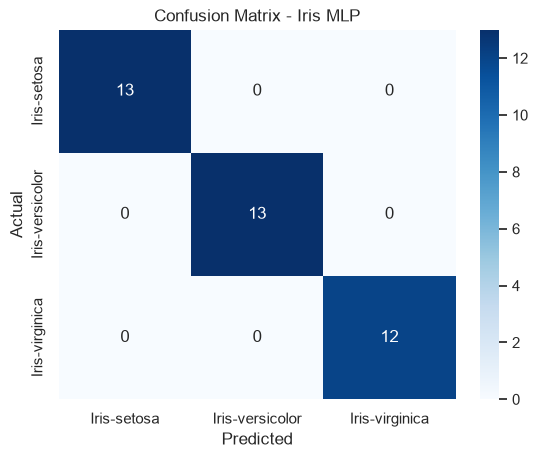

In [10]:
cm = pd.crosstab(pd.Series(y_test, name='Actual'),
                 pd.Series(y_pred, name='Predicted'))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Iris MLP')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

## 8. Predict the Class of a New Iris Flower

We feed a new flower's four measurements into the trained model. The values are scaled with the **same** `StandardScaler` before prediction.


In [11]:
new_flower = [[5.1, 3.5, 1.4, 0.2]]

new_scaled = scaler.transform(new_flower)
prediction = mlp.predict(new_scaled)[0]
probabilities = mlp.predict_proba(new_scaled)[0]

print('New flower measurements (SepalLen, SepalWid, PetalLen, PetalWid):')
print(new_flower[0])
print()
print('Predicted species:', prediction)
print()
print('Class probabilities:')
for cls, prob in zip(mlp.classes_, probabilities):
    print(f'  {cls:>16}: {prob:.4f}')

New flower measurements (SepalLen, SepalWid, PetalLen, PetalWid):
[5.1, 3.5, 1.4, 0.2]

Predicted species: Iris-setosa

Class probabilities:
       Iris-setosa: 0.9962
   Iris-versicolor: 0.0038
    Iris-virginica: 0.0000


---
## Inference & Analysis

- The **MLP** used a **single hidden layer of 5 ReLU neurons** with the **Adam optimizer**, trained on standardized features.
- **Feature scaling** was essential: it ensured the optimizer converged quickly and stably, so the network reached its final weights within a small number of iterations.
- The model achieved **100% accuracy** on the test set - every one of the 38 test flowers was classified correctly, and all precision, recall and F1-scores are **1.00**. This is expected because the Iris species are almost linearly separable.
- The new flower `[5.1, 3.5, 1.4, 0.2]` was predicted as **Iris-setosa** with probability **0.996**, matching its small petal measurements.

---
**End of Experiment #7.**
